In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [ ]:
from google.colab import files
archivos = files.upload()
nom_arch = list(archivos.keys())[0]
pd.read_excel(nom_arch)


datos = pd.read_excel(nom_arch)

display(datos.head())

print("numero de filas", datos.shape[0])
print("numero de columnas", datos.shape[1])
print(datos.columns.tolist())

Saving ExcelFinalConCumplimientoISNT.xlsx to ExcelFinalConCumplimientoISNT.xlsx


,Archivo,Tipo_Ojo,I,S,N,T,Tasa Cumplimiento,I/S,N/S,I*S,...,DiametroY_Disc,DiametroX_Cup,DiametroY_Cup,VCDR,HCDR,RimArea,CupDiscAreaRatio,RimDiscAreaRatio,class,ClasePredicha
0,001.jpg,DERECHO,51,61,43,43,66.666667,0.836066,0.704918,3111,...,415,256,306,0.737349,0.748538,49896,0.554078,0.445922,negativo,Negativo
1,002.jpg,IZQUIERDO,54,67,43,43,66.666667,0.805970,0.641791,3618,...,421,256,303,0.719715,0.748538,51901,0.543073,0.456927,negativo,Negativo
2,003.jpg,IZQUIERDO,51,54,53,72,0.000000,0.944444,0.981481,2754,...,408,319,303,0.742647,0.741860,63703,0.538859,0.461141,negativo,Negativo
3,004.jpg,DERECHO,41,48,38,91,33.333333,0.854167,0.791667,1968,...,325,176,232,0.713846,0.577049,47869,0.386082,0.613918,negativo,Negativo
4,005.jpg,IZQUIERDO,44,48,48,48,0.000000,0.916667,1.000000,2112,...,350,256,258,0.737143,0.727273,44201,0.545238,0.454762,negativo,Negativo


numero de filas 650
numero de columnas 32
['Archivo', 'Tipo_Ojo', 'I', 'S', 'N', 'T', 'Tasa Cumplimiento', 'I/S', 'N/S', 'I*S', 'I*N', 'I*T', 'S*N', 'S*T', 'N*T', 'I^2', 'S^2', 'N^2', 'T^2', 'Area_Disc', 'Area_Cup', 'DiametroX_Disc', 'DiametroY_Disc', 'DiametroX_Cup', 'DiametroY_Cup', 'VCDR', 'HCDR', 'RimArea', 'CupDiscAreaRatio', 'RimDiscAreaRatio', 'class', 'ClasePredicha']


In [ ]:
print("datos faltantes por columna: ")
print(datos.isnull().sum())

print("/ntipos de datos: ")
print(datos.dtypes)

print("\ncantidad de datos por clase")
print(datos["class"].value_counts())

print("\nfilas duplicados: ", datos.duplicated().sum())



datos faltantes por columna: 
Archivo              0
Tipo_Ojo             0
I                    0
S                    0
N                    0
T                    0
Tasa Cumplimiento    0
I/S                  0
N/S                  0
I*S                  0
I*N                  0
I*T                  0
S*N                  0
S*T                  0
N*T                  0
I^2                  0
S^2                  0
N^2                  0
T^2                  0
Area_Disc            0
Area_Cup             0
DiametroX_Disc       0
DiametroY_Disc       0
DiametroX_Cup        0
DiametroY_Cup        0
VCDR                 0
HCDR                 0
RimArea              0
CupDiscAreaRatio     0
RimDiscAreaRatio     0
class                0
ClasePredicha        0
dtype: int64
/ntipos de datos: 
Archivo               object
Tipo_Ojo              object
I                      int64
S                      int64
N                      int64
T                      int64
Tasa Cumplimiento    float64

In [ ]:
# eliminar variables irrevelantes
datoslimpios = datos.drop(
    columns =["Archivo", "ClasePredicha"]
)

X = datoslimpios.drop(columns=["class"])
Y = datoslimpios["class"]

X = pd.get_dummies(
    X,
    columns=["Tipo_Ojo"],
    dtype= int

)

print("tamaño de X: " , X.shape)
print("tamaño de Y: " , Y.shape)

print("\nvariables predictoras", X.columns.tolist())
print("\ncantidad por filas: " , Y.value_counts())



tamaño de X:  (650, 30)
tamaño de Y:  (650,)

variables predictoras ['I', 'S', 'N', 'T', 'Tasa Cumplimiento', 'I/S', 'N/S', 'I*S', 'I*N', 'I*T', 'S*N', 'S*T', 'N*T', 'I^2', 'S^2', 'N^2', 'T^2', 'Area_Disc', 'Area_Cup', 'DiametroX_Disc', 'DiametroY_Disc', 'DiametroX_Cup', 'DiametroY_Cup', 'VCDR', 'HCDR', 'RimArea', 'CupDiscAreaRatio', 'RimDiscAreaRatio', 'Tipo_Ojo_DERECHO', 'Tipo_Ojo_IZQUIERDO']

cantidad por filas:  class
negativo    482
positivo    168
Name: count, dtype: int64


In [ ]:
# importar funcion para dividir los datos
from sklearn.model_selection import train_test_split

# 85% para desarrollo y 15% para test
X_desarrollo, X_test, Y_desarrollo, Y_test = train_test_split(
    X, Y,
    test_size=0.15,
    random_state=42,
    stratify=Y
)

# train y validation
X_train, X_validation, Y_train, Y_validation = train_test_split(
    X_desarrollo, Y_desarrollo,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=Y_desarrollo
)

# mostrar tamaño de cada conjunto
print("Entrenamiento:", X_train.shape)
print("Validacion:", X_validation.shape)
print("Prueba:", X_test.shape)

# revisar clases en cada conjunto
print("\nClases en entrenamiento:")
print(Y_train.value_counts())

print("\nClases en validacion:")
print(Y_validation.value_counts())

print("\nClases en prueba:")
print(Y_test.value_counts())

Entrenamiento: (454, 30)
Validacion: (98, 30)
Prueba: (98, 30)

Clases en entrenamiento:
class
negativo    336
positivo    118
Name: count, dtype: int64

Clases en validacion:
class
negativo    73
positivo    25
Name: count, dtype: int64

Clases en prueba:
class
negativo    73
positivo    25
Name: count, dtype: int64


In [ ]:
# importar funcion para normalizar
from sklearn.preprocessing import MinMaxScaler

# crear normalizador
normaliza = MinMaxScaler()

# aprender minimos y maximos usando training
X_train_norm = normaliza.fit_transform(X_train)

# aplicar normalizacion a validacion y prueba
X_validation_norm = normaliza.transform(X_validation)
X_test_norm = normaliza.transform(X_test)

# mostrar tamaños
print("Entrenamiento normalizado:", X_train_norm.shape)
print("Validacion normalizada:", X_validation_norm.shape)
print("Prueba normalizada:", X_test_norm.shape)


Entrenamiento normalizado: (454, 30)
Validacion normalizada: (98, 30)
Prueba normalizada: (98, 30)


In [ ]:
# reconocedor euclideo minima distancia

# obtener clases disponibles
clases = np.unique(Y_train)

# calcular centro de cada clase usando training

centros = []

for clase in clases:
    datos_clase = X_train_norm[
        Y_train.to_numpy() == clase
    ]

    centro = np.mean(datos_clase, axis=0)
    centros.append(centro)

# convertir centros en una matriz
centros = np.array(centros)

print("Clases:", clases)
print("Tamano de los centros:", centros.shape)


# funcion para clasificar los datos
def reconocer_euclideo(datos_nuevos):

    predicciones = []

    for fila in datos_nuevos:

        distancias = []

        for centro in centros:
            distancia = np.sqrt(np.sum((fila - centro) ** 2))
            distancias.append(distancia)

        posicion = np.argmin(distancias)
        predicciones.append(clases[posicion])

    return np.array(predicciones)


# clasificar entrenamiento, validacion y prueba
pred_train = reconocer_euclideo(X_train_norm)
pred_validation = reconocer_euclideo(X_validation_norm)
pred_test = reconocer_euclideo(X_test_norm)


Clases: ['negativo' 'positivo']
Tamano de los centros: (2, 30)


In [ ]:
# importar metricas
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# calcular accuracy de cada conjunto
accuracy_train = accuracy_score(
    Y_train, pred_train
)

accuracy_validation = accuracy_score(
    Y_validation, pred_validation
)

accuracy_test = accuracy_score(
    Y_test, pred_test
)

print("Accuracy entrenamiento:",
      round(accuracy_train * 100, 2), "%")

print("Accuracy validacion:",
      round(accuracy_validation * 100, 2), "%")

print("Accuracy prueba:",
      round(accuracy_test * 100, 2), "%")


# matriz de confusion para prueba
print("\nMatriz de confusion en prueba:")

print(confusion_matrix(
    Y_test,
    pred_test,
    labels=["negativo", "positivo"]
))

Accuracy entrenamiento: 54.41 %
Accuracy validacion: 57.14 %
Accuracy prueba: 52.04 %

Matriz de confusion en prueba:
[[37 36]
 [11 14]]


In [ ]:
 # calcular sensibilidad para positiva

from sklearn.metrics import recall_score

sensibilidad_train = recall_score(
    Y_train,
    pred_train,
    pos_label="positivo"
)

sensibilidad_validation = recall_score(
    Y_validation,
    pred_validation,
    pos_label="positivo"
)

sensibilidad_test = recall_score(
    Y_test,
    pred_test,
    pos_label="positivo"
)

print("Sensibilidad entrenamiento:",
      round(sensibilidad_train * 100, 2), "%")

print("Sensibilidad validacion:",
      round(sensibilidad_validation * 100, 2), "%")

print("Sensibilidad prueba:",
      round(sensibilidad_test * 100, 2), "%")

Sensibilidad entrenamiento: 57.63 %
Sensibilidad validacion: 64.0 %
Sensibilidad prueba: 56.0 %


In [ ]:
# revisar version de scikit-learn

import sklearn

print("Version de scikit-learn:", sklearn.__version__)


from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.neighbors import NeighborhoodComponentsAnalysis

Version de scikit-learn: 1.6.1


In [ ]:
def fscnca(X, Y, valor_lambda=0.01):


    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y)

    cantidadvariables = X.shape[1]

    clases, etiquetas = np.unique(Y, return_inverse=True)

    mismaclase = etiquetas[:, None] == etiquetas[None, :]
    np.fill_diagonal(mismaclase, False)

    diferencias = X[:, None, :] - X[None, :, :]
    diferencias = diferencias ** 2

    pesosiniciales = np.ones(cantidadvariables) * 0.1

    def calcularerror(pesos):

        distancias = np.sum(
            diferencias * (pesos ** 2)[None, None, :],
            axis=2
        )

        np.fill_diagonal(distancias, np.inf)

        probabilidades = np.exp(-np.minimum(distancias, 700))
        probabilidades[~np.isfinite(distancias)] = 0

        suma = probabilidades.sum(axis=1, keepdims=True)
        probabilidades = probabilidades / np.maximum(suma, 1e-12)

        prob_correcta = np.sum(
            probabilidades * mismaclase,
            axis=1
        )

        error = -np.sum(prob_correcta)
        error += valor_lambda * np.sum(pesos ** 2)

        promedio_total = np.sum(
            probabilidades[:, :, None] * diferencias,
            axis=1
        )

        promedio_correcto = np.sum(
            probabilidades[:, :, None]
            * mismaclase[:, :, None]
            * diferencias,
            axis=1
        )

        gradiente = 2 * pesos * np.sum(
            promedio_correcto
            - prob_correcta[:, None] * promedio_total,
            axis=0
        )

        gradiente += 2 * valor_lambda * pesos

        return error, gradiente


    resultado = minimize(
        calcularerror,
        pesosiniciales,
        method="L-BFGS-B",
        jac=True,
        bounds=[(0, 10)] * cantidadvariables,
        options={"maxiter": 60}
    )

    print("Mensaje:", resultado.message)

    return resultado.x


print("Función FSCNCA actualizada correctamente")

Función FSCNCA actualizada correctamente


In [ ]:
# prueba con 50 filas

X_peque = X_train_norm[:50]
Y_peque = np.asarray(Y_train)[:50]

# calcular pesos de las variables
pesos_prueba = fscnca(
    X_peque,
    Y_peque,
    valor_lambda=0.01
)

# mostrar resultados
print("Prueba terminada")
print("Cantidad de pesos:", len(pesos_prueba))
print(pesos_prueba)

Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Prueba terminada
Cantidad de pesos: 30
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.81745497 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.        ]


In [ ]:
# Si no se ha ejecutado la celda de sintonización, definimos un valor por defecto
if 'lambda_optimo' not in locals():
    lambda_optimo = 0.01

pesos_fscnca = fscnca(
    X_train_norm,
    Y_train,
    valor_lambda=lambda_optimo
)

print("Cantidad de pesos:", len(pesos_fscnca))

Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Cantidad de pesos: 30


Probando lambda = 0.001
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Probando lambda = 0.01
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Probando lambda = 0.1
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Probando lambda = 1
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Probando lambda = 10
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


,Lambda,Mejor_cantidad_variables,Accuracy_validacion
0,0.001,4,0.653061
1,0.010,18,0.683673
2,0.100,9,0.663265
3,1.000,18,0.683673
4,10.000,18,0.683673


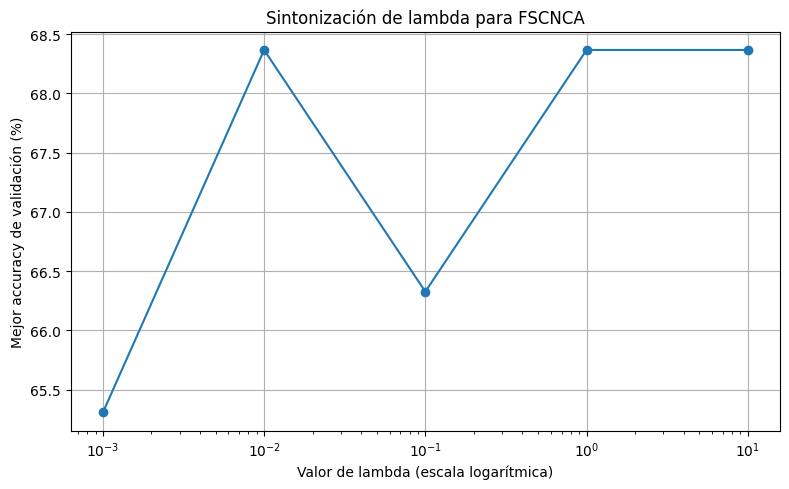

Lambda seleccionado: 0.01
Mejor accuracy de validación: 68.37 %


In [ ]:

# SINTONIZACIÓN DE LAMBDA PARA FSCNCA

valores_lambda = [0.001, 0.01, 0.1, 1, 10]
resultados_lambda = []

for lam in valores_lambda:
    print("Probando lambda =", lam)

    # Calcular pesos usando solamente entrenamiento
    pesos = fscnca(
        X_train_norm,
        Y_train,
        valor_lambda=lam
    )

    # Ordenar variables según sus pesos
    tabla_temp = pd.DataFrame({
        "Variable": list(X.columns),
        "Peso": pesos
    }).sort_values(
        "Peso", ascending=False
    ).reset_index(drop=True)

    mejor_accuracy = -1
    mejor_k = 1

    # Buscar la cantidad de variables con mejor accuracy en VALIDACIÓN
    for k in range(1, len(tabla_temp) + 1):

        variables = tabla_temp["Variable"].iloc[:k].tolist()
        posiciones = [list(X.columns).index(v) for v in variables]

        Xtr = X_train_norm[:, posiciones]
        Xval = X_validation_norm[:, posiciones]

        clases = np.unique(Y_train)
        centroides = []

        for clase in clases:
            datos_clase = Xtr[np.asarray(Y_train) == clase]
            centroides.append(np.mean(datos_clase, axis=0))

        centroides = np.array(centroides)

        predicciones = []

        for fila in Xval:
            distancias = [
                np.sqrt(np.sum((fila - centro) ** 2))
                for centro in centroides
            ]
            predicciones.append(clases[np.argmin(distancias)])

        accuracy = accuracy_score(Y_validation, predicciones)

        if accuracy > mejor_accuracy:
            mejor_accuracy = accuracy
            mejor_k = k

    resultados_lambda.append({
        "Lambda": lam,
        "Mejor_cantidad_variables": mejor_k,
        "Accuracy_validacion": mejor_accuracy
    })

tabla_lambda = pd.DataFrame(resultados_lambda)
display(tabla_lambda)

# Graficar resultados de lambda
plt.figure(figsize=(8, 5))
plt.plot(
    tabla_lambda["Lambda"],
    tabla_lambda["Accuracy_validacion"] * 100,
    marker="o"
)
plt.xscale("log")
plt.xlabel("Valor de lambda (escala logarítmica)")
plt.ylabel("Mejor accuracy de validación (%)")
plt.title("Sintonización de lambda para FSCNCA")
plt.grid(True)
plt.tight_layout()
plt.show()

# Elegir lambda con mayor accuracy de validación
fila_mejor_lambda = tabla_lambda[
    "Accuracy_validacion"
].idxmax()

lambda_optimo = tabla_lambda.loc[
    fila_mejor_lambda, "Lambda"
]

print("Lambda seleccionado:", lambda_optimo)
print(
    "Mejor accuracy de validación:",
    round(
        tabla_lambda.loc[
            fila_mejor_lambda, "Accuracy_validacion"
        ] * 100, 2
    ),
    "%"
)


In [ ]:
# tabla pesos fscnca
tabla_pesos = pd.DataFrame({
    "Variable": list(X.columns),
    "Peso": pesos_fscnca
})

tabla_pesos = tabla_pesos.sort_values(
    by="Peso",
    ascending=False
).reset_index(drop=True)

display(tabla_pesos)

,Variable,Peso
0,N/S,10.000000
1,Area_Disc,8.641055
2,I^2,2.636035
3,Tasa Cumplimiento,2.416079
4,N^2,2.179792
5,N,0.000000
6,I/S,0.000000
7,T,0.000000
8,I*N,0.000000
9,I*S,0.000000


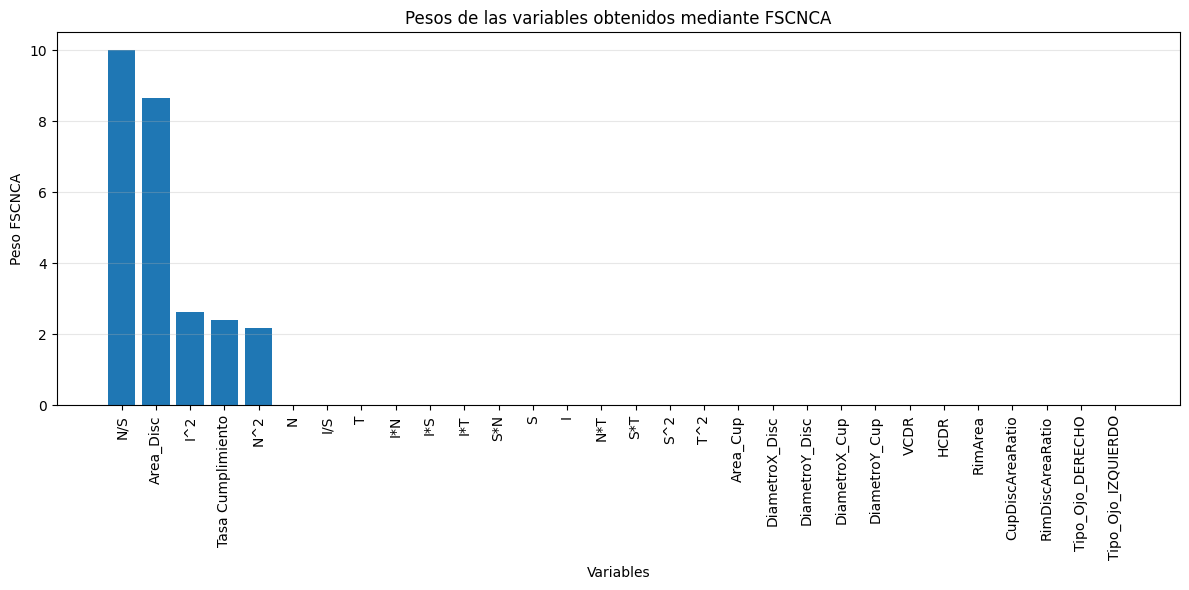

In [ ]:
# GRAFICA DE PESOS FSCNCA

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    tabla_pesos["Variable"],
    tabla_pesos["Peso"]
)

plt.xticks(rotation=90)
plt.xlabel("Variables")
plt.ylabel("Peso FSCNCA")
plt.title("Pesos de las variables obtenidos mediante FSCNCA")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

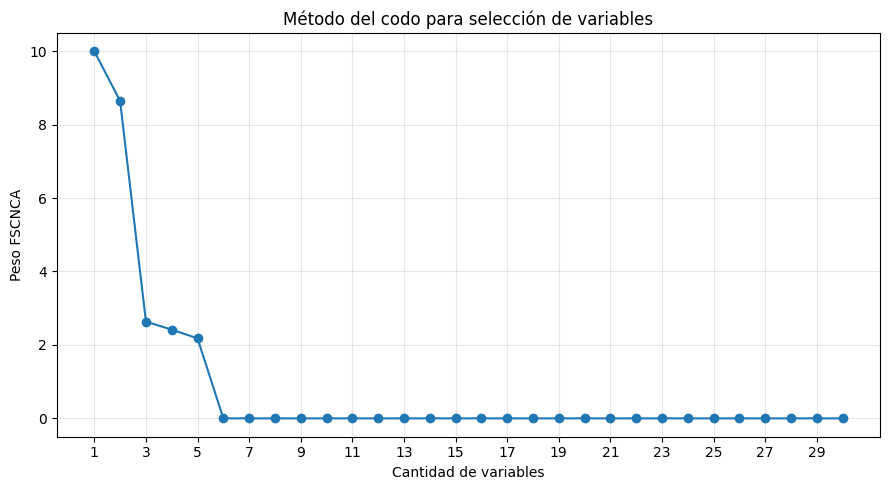

Cantidad de variables sugerida por el método del codo: 6
Variables seleccionadas:


,Variable,Peso
0,N/S,10.000000
1,Area_Disc,8.641055
2,I^2,2.636035
3,Tasa Cumplimiento,2.416079
4,N^2,2.179792
5,N,0.000000


In [ ]:
# METODO DEL CODO FSCNCA

import numpy as np
import matplotlib.pyplot as plt

pesos_ordenados = tabla_pesos["Peso"].values

# graficar pesos ordenados
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(pesos_ordenados) + 1),
    pesos_ordenados,
    marker="o"
)

plt.xlabel("Cantidad de variables")
plt.ylabel("Peso FSCNCA")
plt.title("Método del codo para selección de variables")
plt.xticks(range(1, len(pesos_ordenados) + 1, 2))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Buscar el punto más alejado de la línea entre los extremos
x = np.arange(1, len(pesos_ordenados) + 1)
y = pesos_ordenados

distancias = np.abs(
    (y[-1] - y[0]) * x
    - (x[-1] - x[0]) * y
    + x[-1] * y[0]
    - y[-1] * x[0]
) / np.sqrt(
    (y[-1] - y[0])**2 + (x[-1] - x[0])**2
)

indice_codo = np.argmax(distancias)
cantidad_codo = indice_codo + 1

print("Cantidad de variables sugerida por el método del codo:", cantidad_codo)
print("Variables seleccionadas:")

display(tabla_pesos.head(cantidad_codo))

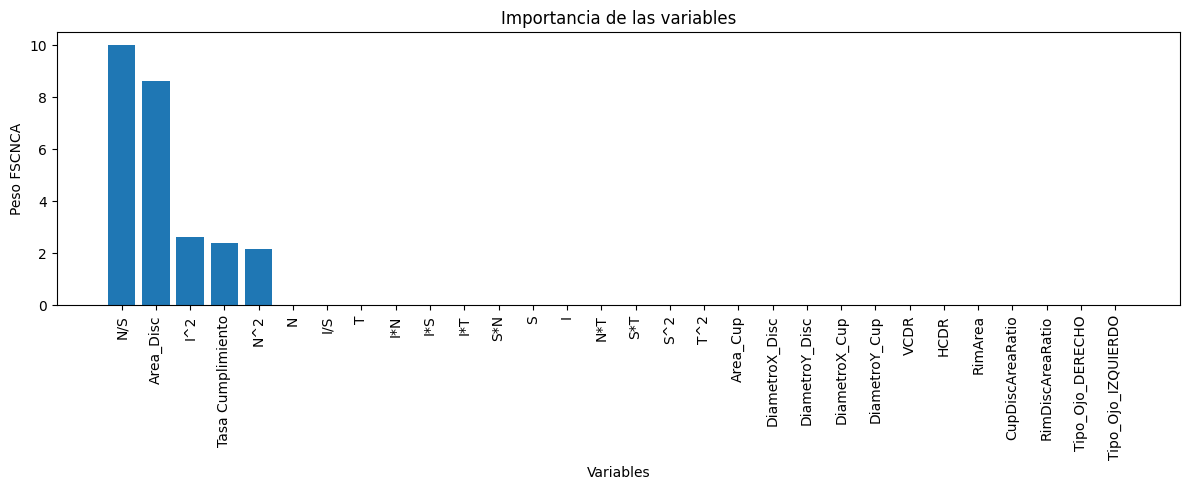

In [ ]:
resultados_fscnca = []

#figura pesos de las variable fscnca
plt.figure(figsize=(12, 5))

plt.bar(
    tabla_pesos["Variable"],
    tabla_pesos["Peso"]
)

plt.xticks(rotation=90)
plt.xlabel("Variables")
plt.ylabel("Peso FSCNCA")
plt.title("Importancia de las variables")

plt.tight_layout()
plt.show()

In [ ]:
# guardar resultados de cada prueba
resultados_fscnca = []

# probar numeros hasta usar todas las variables
for k in range(1, len(tabla_pesos) + 1):


    # elegir primeras k variables de la tabla
    variables_elegidas = tabla_pesos["Variable"].iloc[:k].tolist()

    # buscar la posición de cada variable
    posiciones = []

    for variable in variables_elegidas:
        posiciones.append(list(X.columns).index(variable))

    # crear datos con las variables elegidas
    X_train_seleccion = X_train_norm[:, posiciones]
    X_val_seleccion = X_validation_norm[:, posiciones]

    # calcular el centro de cada clase con training
    clases = np.unique(Y_train)
    centroides = []

    for clase in clases:
        datos_clase = X_train_seleccion[
            np.asarray(Y_train) == clase
        ]

        centro = np.mean(datos_clase, axis=0)
        centroides.append(centro)

    centroides = np.array(centroides)

    # clasificar los datos de validación
    predicciones = []

    for fila in X_val_seleccion:
        distancias = []

        for centro in centroides:
            distancia = np.sqrt(np.sum((fila - centro) ** 2))
            distancias.append(distancia)

        posicion = np.argmin(distancias)
        predicciones.append(clases[posicion])

    # ccalcular accuracy y sensibilidad
    accuracy = accuracy_score(Y_validation, predicciones)

    sensibilidad = recall_score(
        Y_validation,
        predicciones,
        pos_label="positivo",
        zero_division=0
    )

    # guardar resultados
    resultados_fscnca.append({
        "Cantidad_variables": k,
        "Accuracy": accuracy,
        "Sensibilidad": sensibilidad
    })

tabla_resultados_fscnca = pd.DataFrame(resultados_fscnca)
display(tabla_resultados_fscnca)

,Cantidad_variables,Accuracy,Sensibilidad
0,1,0.642857,0.40
1,2,0.591837,0.48
2,3,0.602041,0.48
3,4,0.622449,0.44
4,5,0.632653,0.44
5,6,0.632653,0.44
6,7,0.653061,0.48
7,8,0.663265,0.44
8,9,0.663265,0.44
9,10,0.663265,0.44


In [ ]:
# buscar la fila con mayor accuracy
mejor_accuracy = tabla_resultados_fscnca[
    "Accuracy"
].idxmax()

# buscar la fila con mayor sensibilidad
mejor_sensibilidad = tabla_resultados_fscnca[
    "Sensibilidad"
].idxmax()

print("MEJOR RESULTADO DEL ACCURACY ")
display(
    tabla_resultados_fscnca.loc[[mejor_accuracy]]
)

print("MEJOR RESULTADO DE SENSIBILIDAD")
display(
    tabla_resultados_fscnca.loc[[mejor_sensibilidad]]
)

MEJOR RESULTADO DEL ACCURACY 


,Cantidad_variables,Accuracy,Sensibilidad
17,18,0.683673,0.44


MEJOR RESULTADO DE SENSIBILIDAD


,Cantidad_variables,Accuracy,Sensibilidad
29,30,0.571429,0.64


In [ ]:
# guardar las 18 variables con mayor peso FSCNCA

mejores_variables = tabla_pesos["Variable"].iloc[:18].tolist()

print("Las 18 variables seleccionadas son:")

for variable in mejores_variables:
    print("-", variable)

Las 18 variables seleccionadas son:
- N/S
- Area_Disc
- I^2
- Tasa Cumplimiento
- N^2
- N
- I/S
- T
- I*N
- I*S
- I*T
- S*N
- S
- I
- N*T
- S*T
- S^2
- T^2


In [ ]:
# guardar las 18 variables

mejores_variables = tabla_pesos["Variable"].iloc[:18].tolist()

# Crear una tabla con las variables seleccionadas
tabla_seleccionadas = pd.DataFrame({
    "Numero": range(1, 19),
    "Variable_seleccionada": mejores_variables
})

display(tabla_seleccionadas)

# Guardar la tabla en un archivo Excel
tabla_seleccionadas.to_excel(
    "Variables_seleccionadas_FSCNCA.xlsx",
    index=False
)



,Numero,Variable_seleccionada
0,1,N/S
1,2,Area_Disc
2,3,I^2
3,4,Tasa Cumplimiento
4,5,N^2
5,6,N
6,7,I/S
7,8,T
8,9,I*N
9,10,I*S


In [ ]:
# función para clasificar usando distancia euclidiana y calcular el centro de cada clase con training

def clasificar_forward(X_train, Y_train, X_val):

    # obtener las clases disponibles
    clases = np.unique(Y_train)

    # guardar los centros de las clases
    centroides = []

    for clase in clases:

        # seleccionar filas que pertenecen a esa clase
        datos_clase = X_train[
            np.asarray(Y_train) == clase
        ]

        # calcular el centro de la clase
        centro = np.mean(datos_clase, axis=0)

        centroides.append(centro)

    centroides = np.array(centroides)

    # clasificar las filas de validación
    predicciones = []

    for fila in X_val:

        distancias = []

        for centro in centroides:

            distancia = np.sqrt(
                np.sum((fila - centro) ** 2)
            )

            distancias.append(distancia)

        # elegir la clase cuyo centro esté más cerca
        posicion = np.argmin(distancias)

        predicciones.append(clases[posicion])

    return np.array(predicciones)

In [ ]:
print("Datos:", X.shape)
print("Etiquetas:", Y.shape)
print("Clasificador:", clasificar_forward)

Datos: (650, 30)
Etiquetas: (650,)
Clasificador: <function clasificar_forward at 0x7dd6c27f1d00>


In [ ]:


X_desarrollo, X_test_rep, Y_desarrollo, Y_test_rep = train_test_split(
    X, Y, test_size=0.15, random_state=100, stratify=Y
)

X_train_rep, X_val_rep, Y_train_rep, Y_val_rep = train_test_split(
    X_desarrollo, Y_desarrollo,
    test_size=0.15 / 0.85,
    random_state=200,
    stratify=Y_desarrollo
)

normalizador_rep = MinMaxScaler()

X_train_rep = normalizador_rep.fit_transform(X_train_rep)
X_val_rep = normalizador_rep.transform(X_val_rep)
X_test_rep = normalizador_rep.transform(X_test_rep)

pred_train = clasificar_forward(
    X_train_rep, Y_train_rep, X_train_rep
)

pred_val = clasificar_forward(
    X_train_rep, Y_train_rep, X_val_rep
)

pred_test = clasificar_forward(
    X_train_rep, Y_train_rep, X_test_rep
)

print("Accuracy entrenamiento:", accuracy_score(Y_train_rep, pred_train))
print("Accuracy validación:", accuracy_score(Y_val_rep, pred_val))
print("Accuracy prueba:", accuracy_score(Y_test_rep, pred_test))

Accuracy entrenamiento: 0.539647577092511
Accuracy validación: 0.5408163265306123
Accuracy prueba: 0.4897959183673469


In [ ]:
# probar el reconocedor con todas las variables
predicciones_val = clasificar_forward(
    X_train_norm,
    Y_train,
    X_validation_norm
)

accuracy_val = accuracy_score(
    Y_validation,
    predicciones_val
)

print("Accuracy de validación:", accuracy_val)

print("Datos de validación:", len(Y_validation))
print("Predicciones correctas:", sum(Y_validation == predicciones_val))

Accuracy de validación: 0.5714285714285714
Datos de validación: 98
Predicciones correctas: 56


In [ ]:
# FORWARD SELECTION: ACCURACY

resultados_forward = []
variables_elegidas = []
variables_disponibles = list(X.columns)

for paso in range(len(variables_disponibles)):

    print("Paso", paso + 1, "de", len(variables_disponibles))

    mejor_variable = None
    mejor_accuracy = -1
    mejor_sensibilidad = 0

    for variable in variables_disponibles:

        if variable not in variables_elegidas:

            prueba_variables = variables_elegidas + [variable]

            posiciones = [
                list(X.columns).index(v)
                for v in prueba_variables
            ]

            X_train_forward = X_train_norm[:, posiciones]
            X_val_forward = X_validation_norm[:, posiciones]

            predicciones = clasificar_forward(
                X_train_forward,
                Y_train,
                X_val_forward
            )

            accuracy = accuracy_score(
                Y_validation,
                predicciones
            )

            sensibilidad = recall_score(
                Y_validation,
                predicciones,
                pos_label="positivo",
                zero_division=0
            )

            if accuracy > mejor_accuracy:
                mejor_accuracy = accuracy
                mejor_sensibilidad = sensibilidad
                mejor_variable = variable

    variables_elegidas.append(mejor_variable)

    resultados_forward.append({
        "Cantidad_variables": len(variables_elegidas),
        "Variable_agregada": mejor_variable,
        "Accuracy": mejor_accuracy,
        "Sensibilidad": mejor_sensibilidad
    })

    print("Variable agregada:", mejor_variable)
    print("Accuracy de validación:", round(mejor_accuracy * 100, 2), "%")

tabla_forward = pd.DataFrame(resultados_forward)

display(tabla_forward)

Paso 1 de 30
Variable agregada: VCDR
Accuracy de validación: 75.51 %
Paso 2 de 30
Variable agregada: CupDiscAreaRatio
Accuracy de validación: 75.51 %
Paso 3 de 30
Variable agregada: S*T
Accuracy de validación: 76.53 %
Paso 4 de 30
Variable agregada: DiametroY_Cup
Accuracy de validación: 75.51 %
Paso 5 de 30
Variable agregada: RimDiscAreaRatio
Accuracy de validación: 75.51 %
Paso 6 de 30
Variable agregada: I*T
Accuracy de validación: 76.53 %
Paso 7 de 30
Variable agregada: S^2
Accuracy de validación: 76.53 %
Paso 8 de 30
Variable agregada: I
Accuracy de validación: 75.51 %
Paso 9 de 30
Variable agregada: N
Accuracy de validación: 75.51 %
Paso 10 de 30
Variable agregada: I*S
Accuracy de validación: 75.51 %
Paso 11 de 30
Variable agregada: I^2
Accuracy de validación: 75.51 %
Paso 12 de 30
Variable agregada: HCDR
Accuracy de validación: 77.55 %
Paso 13 de 30
Variable agregada: S
Accuracy de validación: 75.51 %
Paso 14 de 30
Variable agregada: I*N
Accuracy de validación: 76.53 %
Paso 15 de 

,Cantidad_variables,Variable_agregada,Accuracy,Sensibilidad
0,1,VCDR,0.755102,0.12
1,2,CupDiscAreaRatio,0.755102,0.04
2,3,S*T,0.765306,0.08
3,4,DiametroY_Cup,0.755102,0.04
4,5,RimDiscAreaRatio,0.755102,0.04
5,6,I*T,0.765306,0.08
6,7,S^2,0.765306,0.08
7,8,I,0.755102,0.04
8,9,N,0.755102,0.04
9,10,I*S,0.755102,0.04


In [ ]:
tabla_forward = pd.DataFrame(resultados_forward)

display(tabla_forward)

print("Tabla de Forward Selection creada")

,Cantidad_variables,Variable_agregada,Accuracy,Sensibilidad
0,1,VCDR,0.755102,0.12
1,2,CupDiscAreaRatio,0.755102,0.04
2,3,S*T,0.765306,0.08
3,4,DiametroY_Cup,0.755102,0.04
4,5,RimDiscAreaRatio,0.755102,0.04
5,6,I*T,0.765306,0.08
6,7,S^2,0.765306,0.08
7,8,I,0.755102,0.04
8,9,N,0.755102,0.04
9,10,I*S,0.755102,0.04


Tabla de Forward Selection creada


In [ ]:
# elegir la cantidad de variables con mayor accuracy de validación

mejor_accuracy = tabla_forward["Accuracy"].max()

filas_mejores = tabla_forward[
    tabla_forward["Accuracy"] == mejor_accuracy
]

# si hay empate en accuracy, elegir menos variables
mejor_fila = filas_mejores.iloc[0]

mejor_k_forward = int(
    mejor_fila["Cantidad_variables"]
)

mejores_variables_forward = tabla_forward[
    "Variable_agregada"
].iloc[:mejor_k_forward].tolist()

print("Mejor cantidad de variables:", mejor_k_forward)

print(
    "Accuracy de validación:",
    round(mejor_fila["Accuracy"] * 100, 2),
    "%"
)

print("\nVariables seleccionadas:")

for variable in mejores_variables_forward:
    print(variable)

Mejor cantidad de variables: 12
Accuracy de validación: 77.55 %

Variables seleccionadas:
VCDR
CupDiscAreaRatio
S*T
DiametroY_Cup
RimDiscAreaRatio
I*T
S^2
I
N
I*S
I^2
HCDR


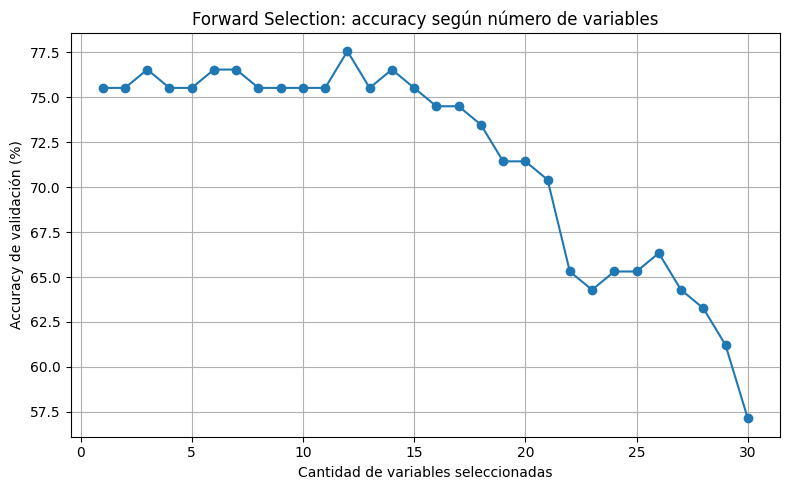

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabla_forward["Cantidad_variables"],
    tabla_forward["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Cantidad de variables seleccionadas")
plt.ylabel("Accuracy de validación (%)")
plt.title("Forward Selection: accuracy según número de variables")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# guardar resultados en un archivo Excel

with pd.ExcelWriter("Resultados_Seleccion_Variables.xlsx") as writer:

    tabla_pesos.to_excel(
        writer,
        sheet_name="Pesos_FSCNCA",
        index=False
    )

    tabla_resultados_fscnca.to_excel(
        writer,
        sheet_name="Evaluacion_FSCNCA",
        index=False
    )

    tabla_forward.to_excel(
        writer,
        sheet_name="Forward_Selection",
        index=False
    )



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, recall_score
import numpy as np
import pandas as pd


In [ ]:
# cantidad de repeticiones
numero_repeticiones = 150

# guardar resultados
resultados_150 = []

# repetir el experimento 150 veces
for repeticion in range(numero_repeticiones):

    print("Ejecución", repeticion + 1, "de", numero_repeticiones)

    # crear una nueva división de los datos
    X_desarrollo, X_test_rep, Y_desarrollo, Y_test_rep = train_test_split(
        X, Y,
        test_size=0.15,
        random_state=100 + repeticion,
        stratify=Y
    )

    X_train_rep, X_val_rep, Y_train_rep, Y_val_rep = train_test_split(
        X_desarrollo, Y_desarrollo,
        test_size=0.15 / 0.85,
        random_state=200 + repeticion,
        stratify=Y_desarrollo
    )

    # normalizar
    normalizador_rep = MinMaxScaler()

    X_train_rep = normalizador_rep.fit_transform(X_train_rep)
    X_val_rep = normalizador_rep.transform(X_val_rep)
    X_test_rep = normalizador_rep.transform(X_test_rep)


    # FSCNCA


    pesos_rep = fscnca(
        X_train_rep,
        Y_train_rep,
        valor_lambda = lambda_optimo
    )

    # ordenar variables de mayor a menor peso
    tabla_rep = pd.DataFrame({
        "Variable": list(X.columns),
        "Peso": pesos_rep
    })

    tabla_rep = tabla_rep.sort_values(
        by="Peso",
        ascending=False
    ).reset_index(drop=True)

    mejor_accuracy_rep = -1
    mejor_k_rep = 1

    # probar diferentes cantidades de variables
    for k in range(1, len(X.columns) + 1):

        variables = tabla_rep["Variable"].iloc[:k].tolist()
        posiciones = [list(X.columns).index(v) for v in variables]

        Xtr = X_train_rep[:, posiciones]
        Xval = X_val_rep[:, posiciones]

        pred_val = clasificar_forward(
            Xtr,
            Y_train_rep,
            Xval
        )

        accuracy = accuracy_score(Y_val_rep, pred_val)

        if accuracy > mejor_accuracy_rep:
            mejor_accuracy_rep = accuracy
            mejor_k_rep = k

    # evaluar FSCNCA usando el k elegido
    variables_fscnca = tabla_rep["Variable"].iloc[:mejor_k_rep].tolist()
    posiciones_fscnca = [
        list(X.columns).index(v) for v in variables_fscnca
    ]

    pred_test_fscnca = clasificar_forward(
        X_train_rep[:, posiciones_fscnca],
        Y_train_rep,
        X_test_rep[:, posiciones_fscnca]
    )

    acc_test_fscnca = accuracy_score(Y_test_rep, pred_test_fscnca)

    sens_test_fscnca = recall_score(
        Y_test_rep,
        pred_test_fscnca,
        pos_label="positivo",
        zero_division=0
    )


    # FORWARD SELECTION


    variables_elegidas = []
    variables_disponibles = list(X.columns)
    historial_forward = []

    # agregar una variable en cada paso
    for paso in range(len(variables_disponibles)):

        mejor_variable = None
        mejor_sensibilidad = -1
        mejor_accuracy_forward = 0

        for variable in variables_disponibles:

            if variable not in variables_elegidas:

                prueba_variables = variables_elegidas + [variable]

                posiciones = [
                    list(X.columns).index(v)
                    for v in prueba_variables
                ]

                pred_val = clasificar_forward(
                    X_train_rep[:, posiciones],
                    Y_train_rep,
                    X_val_rep[:, posiciones]
                )

                sensibilidad = recall_score(
                    Y_val_rep,
                    pred_val,
                    pos_label="positivo",
                    zero_division=0
                )

                accuracy = accuracy_score(Y_val_rep, pred_val)

                if sensibilidad > mejor_sensibilidad:
                    mejor_sensibilidad = sensibilidad
                    mejor_accuracy_forward = accuracy
                    mejor_variable = variable

        variables_elegidas.append(mejor_variable)

        historial_forward.append({
            "Cantidad": len(variables_elegidas),
            "Sensibilidad": mejor_sensibilidad,
            "Accuracy": mejor_accuracy_forward
        })

    # elegir el número de variables con mejor sensibilidad en validación
    tabla_forward_rep = pd.DataFrame(historial_forward)

    mejor_fila = tabla_forward_rep["Sensibilidad"].idxmax()
    mejor_k_forward = int(
        tabla_forward_rep.loc[mejor_fila, "Cantidad"]
    )

    variables_forward = variables_elegidas[:mejor_k_forward]

    posiciones_forward = [
        list(X.columns).index(v) for v in variables_forward
    ]

    # Evaluar Forward Selection en prueba
    pred_test_forward = clasificar_forward(
        X_train_rep[:, posiciones_forward],
        Y_train_rep,
        X_test_rep[:, posiciones_forward]
    )

    acc_test_forward = accuracy_score(Y_test_rep, pred_test_forward)

    sens_test_forward = recall_score(
        Y_test_rep,
        pred_test_forward,
        pos_label="positivo",
        zero_division=0
    )

    # guardar los resultados
    resultados_150.append({
        "Repeticion": repeticion + 1,
        "K_FSCNCA": mejor_k_rep,
        "Accuracy_FSCNCA": acc_test_fscnca,
        "Sensibilidad_FSCNCA": sens_test_fscnca,
        "K_Forward": mejor_k_forward,
        "Accuracy_Forward": acc_test_forward,
        "Sensibilidad_Forward": sens_test_forward
    })


Ejecución 1 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 2 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 3 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 4 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 5 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 6 de 150
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Ejecución 7 de 150
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Ejecución 8 de 150
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Ejecución 9 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 10 de 150
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Ejecución 11 de 150
Mensaje: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Ejecución 12 de 150
Mensaje: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Ejecución 13 de 150
Mensaje: CONVERGENCE: REL

In [ ]:
tabla_150 = pd.DataFrame(resultados_150)

display(tabla_150.head())
print("Cantidad de ejecuciones realizadas:", len(tabla_150))

,Repeticion,K_FSCNCA,Accuracy_FSCNCA,Sensibilidad_FSCNCA,K_Forward,Accuracy_Forward,Sensibilidad_Forward
0,1,3,0.551020,0.60,1,0.489796,0.56
1,2,29,0.642857,0.68,1,0.244898,0.80
2,3,4,0.683673,0.56,1,0.551020,0.68
3,4,13,0.642857,0.68,1,0.540816,0.76
4,5,29,0.612245,0.68,16,0.663265,0.80


Cantidad de ejecuciones realizadas: 150


In [ ]:
# resumen de las 150 ejecuciones
resumen_150 = tabla_150.drop(
    columns=["Repeticion"]
).agg(["mean", "std"]).T

resumen_150.columns = ["Promedio", "Desviacion_estandar"]

display(resumen_150)

,Promedio,Desviacion_estandar
K_FSCNCA,9.740000,9.472978
Accuracy_FSCNCA,0.639660,0.046949
Sensibilidad_FSCNCA,0.562667,0.116289
K_Forward,2.033333,2.389621
Accuracy_Forward,0.427347,0.109065
Sensibilidad_Forward,0.804267,0.092354


In [ ]:
with pd.ExcelWriter("Resultados_150_Ejecuciones.xlsx") as writer:

    tabla_150.to_excel(
        writer,
        sheet_name="Resultados_por_ejecucion",
        index=False
    )

    resumen_150.to_excel(
        writer,
        sheet_name="Promedio_y_desviacion"
    )

print("Archivo Excel creado correctamente")

Archivo Excel creado correctamente


In [ ]:
print("Variables predictoras:", X.shape[1])
print("Filas de entrenamiento:", X_train.shape[0])
print("Filas de validación:", X_validation.shape[0])
print("Filas de prueba:", X_test.shape[0])

print("\nDistribución de clases:")
print(Y.value_counts())

print("\n¿Existen valores faltantes en X?")
print(X.isnull().sum().sum())

Variables predictoras: 30
Filas de entrenamiento: 454
Filas de validación: 98
Filas de prueba: 98

Distribución de clases:
class
negativo    482
positivo    168
Name: count, dtype: int64

¿Existen valores faltantes en X?
0


In [ ]:
from google.colab import files
files.download("Resultados_150_Ejecuciones.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>